# <b>Task 2.1 - Interpretable Market Classes.</b>

Discovery of market classes that separate Binance maker trades by expected markout and turnover.

**Methodology:** for each feature - compute per-trade value using only data available at trade time, bucket by quantiles, evaluate weighted PnL per bucket vs unconditional baseline, test stability across time periods, run KS-test for statistical significance.

**Features tested:**
- Data-driven: spread, OBI, trade flow, liquidation flow, volatility.
- Literature-based: OFI (Cont 2014), VPIN (Easley 2012), Amihud (2002), microprice deviation (Stoikov 2018).

## <b>Import Libraries.</b>

In [1]:
import polars as pl
import utilities as utils

## <b>Global Variables.</b>

In [2]:
# Params.
HORIZONS            = [30, 120, 300]
REBATE_BPS          = 0.5
CLIPPED_BOUND       = 100_000

In [3]:
# Paths for BTCUSDT.
PATH_BINANCE_PERP_BTCUSDT_LOB       = r'data\binance_booktickers\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_LIQUID    = r'data\binance_liquidations\perp_btcusdt.parquet'
PATH_BYBIT_PERP_BTCUSDT_LIQUID      = r'data\bybit_liquidations\btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_TRADES    = r'data\binance_trades\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_MARKOUT   = r'data\processed\btc_markout.parquet'

# Paths for ETHUSDT.
PATH_BINANCE_PERP_ETHUSDT_LOB       = r'data\binance_booktickers\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_LIQUID    = r'data\binance_liquidations\perp_ethusdt.parquet'
PATH_BYBIT_PERP_ETHUSDT_LIQUID      = r'data\bybit_liquidations\ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_TRADES    = r'data\binance_trades\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_MARKOUT   = r'data\processed\eth_markout.parquet'

# All .parquet files.
PARQUET_FILES = {
    "binance_perp_btcusdt_lob": PATH_BINANCE_PERP_BTCUSDT_LOB,
    "binance_perp_btcusdt_liquid": PATH_BINANCE_PERP_BTCUSDT_LIQUID,
    "bybit_perp_btcusdt_liquid": PATH_BYBIT_PERP_BTCUSDT_LIQUID,
    "binance_perp_btcusdt_trades": PATH_BINANCE_PERP_BTCUSDT_TRADES,
    "binance_perp_btcusdt_markout": PATH_BINANCE_PERP_BTCUSDT_MARKOUT,

    "binance_perp_ethusdt_lob": PATH_BINANCE_PERP_ETHUSDT_LOB,
    "binance_perp_ethusdt_liquid": PATH_BINANCE_PERP_ETHUSDT_LIQUID,
    "bybit_perp_ethusdt_liquid": PATH_BYBIT_PERP_ETHUSDT_LIQUID,
    "binance_perp_ethusdt_trades": PATH_BINANCE_PERP_ETHUSDT_TRADES,
    "binance_perp_ethusdt_markout": PATH_BINANCE_PERP_ETHUSDT_MARKOUT
}

In [4]:
lf_lob          = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LOB)
lf_trades       = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_TRADES)
lf_markout      = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_MARKOUT)
lf_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_BTCUSDT_LIQUID)
lf_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LIQUID)

## <b>Class 1 - Spread.</b>

`half_spread = (ask - bid) / (ask + bid)`. 

Wide spread signals deteriorating liquidity. Hypothesis: maker loses more when spread is widening (transition zone), but earns on extreme widening (post-shock reversion).

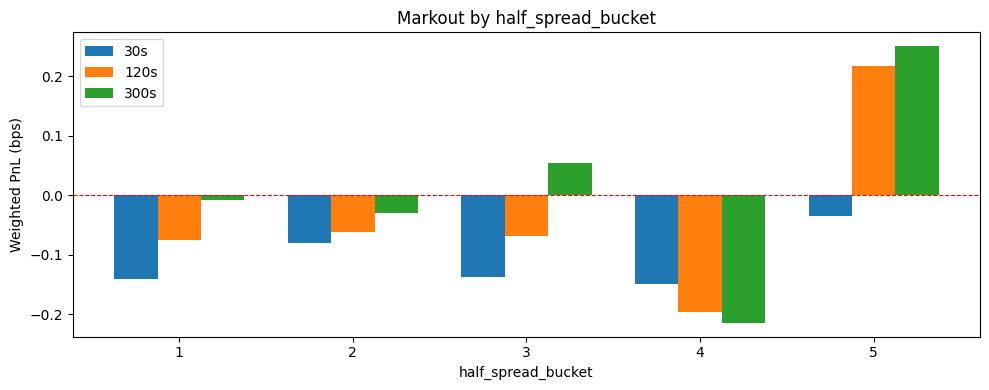

--- Stability ---
Train (Nov-Jan):


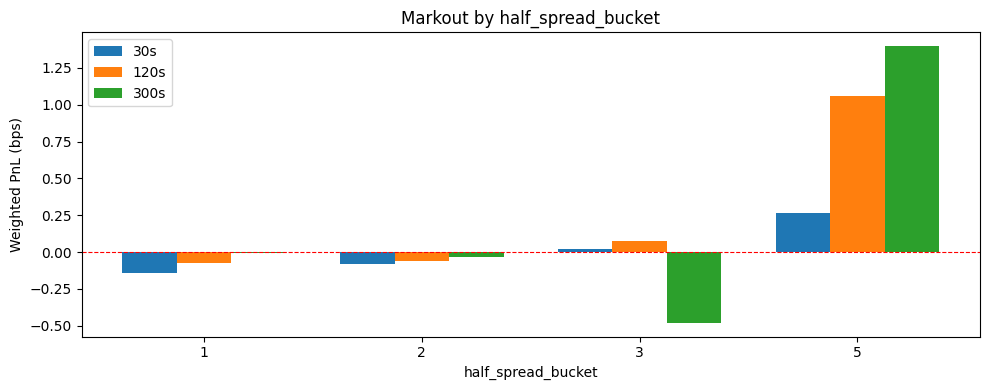

Validation (Feb-Apr):


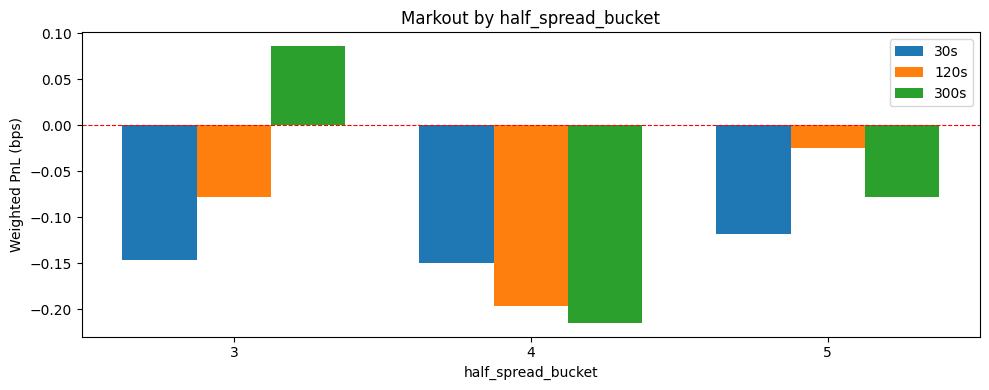

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.03,1.2338e-130
2,0.0199,1.5537e-57
3,0.004,0.008732
4,0.0069,2.5697e-7
5,0.0485,0.0


In [ ]:
# 1. Spread.

df = utils.add_spread_feature(lf_lob=lf_lob, lf_markout=lf_markout)
df = utils.add_quantile_buckets(df, "half_spread", n_buckets=5)

result = utils.evaluate_class(df, "half_spread_bucket")
display(result)
utils.plot_class(result, "half_spread_bucket")

print("--- Stability ---")
r_train, r_val = utils.evaluate_class_by_period(df, "half_spread_bucket")

print("Train (Nov-Jan):")
utils.plot_class(r_train, "half_spread_bucket")

print("Validation (Feb-Apr):")
utils.plot_class(r_val, "half_spread_bucket")

print("--- KS-test ---")
display(utils.ks_test_class(df, "half_spread_bucket"))

## <b>Class 2 - Order Book Imbalance.</b>

`OBI = bid_amount / (bid_amount + ask_amount)`. 

Measures pressure asymmetry at best level. OBI > 0.5 = bid-heavy (buy pressure), OBI < 0.5 = ask-heavy (sell pressure).

obi_bucket,turnover,w_pnl_30s,w_pnl_120s,w_pnl_300s,turnover_pct
u8,f32,f32,f32,f32,f32
1,2.3953e11,-0.1755,-0.098,-0.0799,11.33
2,5.0532e11,-0.1134,-0.0667,-0.0553,23.91
3,6.2689e11,-0.0886,-0.0138,0.0448,29.66
4,5.0357e11,-0.1235,-0.064,-0.017,23.82
5,2.3853e11,-0.0553,0.0675,0.199,11.28


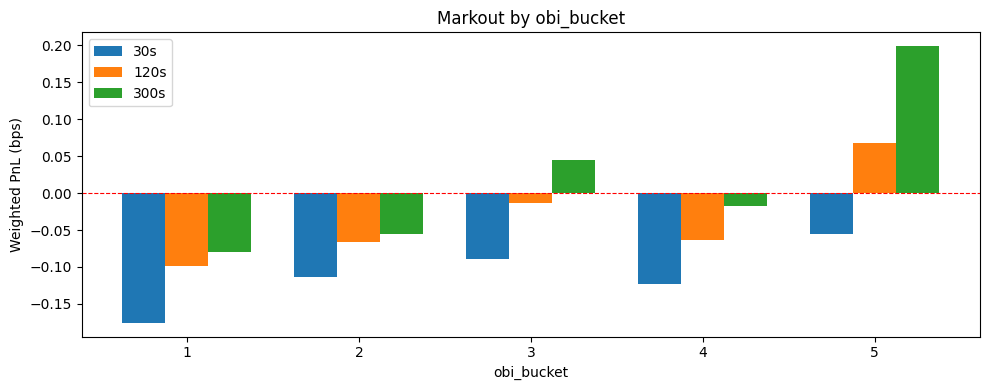

--- Stability ---
Train (Nov-Jan):


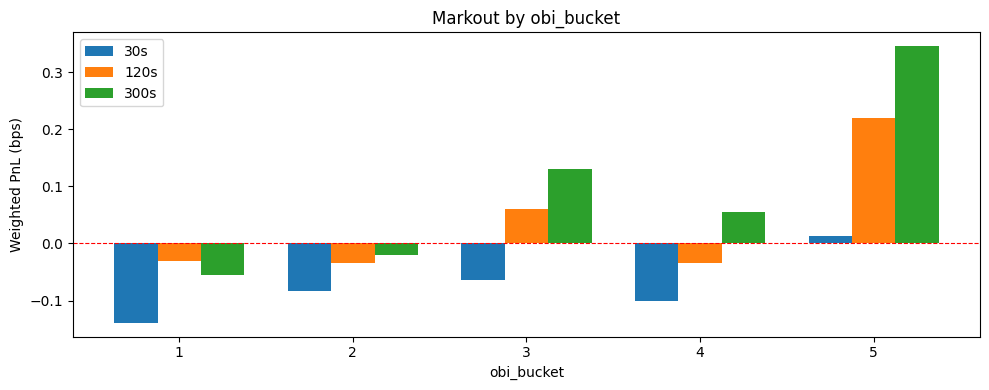

Validation (Feb-Apr):


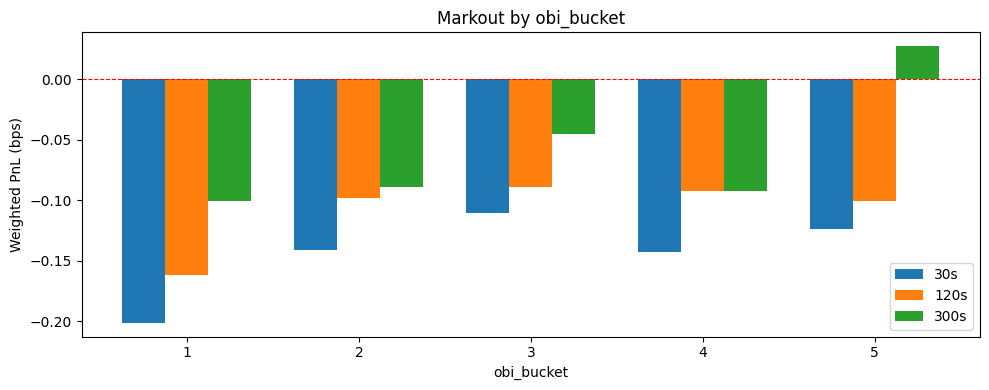

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0149,2.2237e-32
2,0.003,0.099034
3,0.0161,6.5675e-38
4,0.0079,1.5452e-9
5,0.0073,3.0863e-8


In [ ]:
# 2. Order Book Imbalance.

df = utils.add_obi_feature(lf_lob=lf_lob, lf_markout=lf_markout)
df = utils.add_quantile_buckets(df, "obi", n_buckets=5)

result = utils.evaluate_class(df, "obi_bucket")
display(result)
utils.plot_class(result, "obi_bucket")

print("--- Stability ---")
r_train, r_val = utils.evaluate_class_by_period(df, "obi_bucket")

print("Train (Nov-Jan):")
utils.plot_class(r_train, "obi_bucket")

print("Validation (Feb-Apr):")
utils.plot_class(r_val, "obi_bucket")

print("--- KS-test ---")
display(utils.ks_test_class(df, "obi_bucket"))

## <b>Class 3 - Normalized Trade Flow.</b>

`flow = Σ(sign × notional) / Σ(|notional|)` over different time windows. 

Bounded [-1, +1]. Measures how one-sided recent trading activity is. Strong directional flow = likely informed trading = toxic for maker.


=== Window: 1s ===


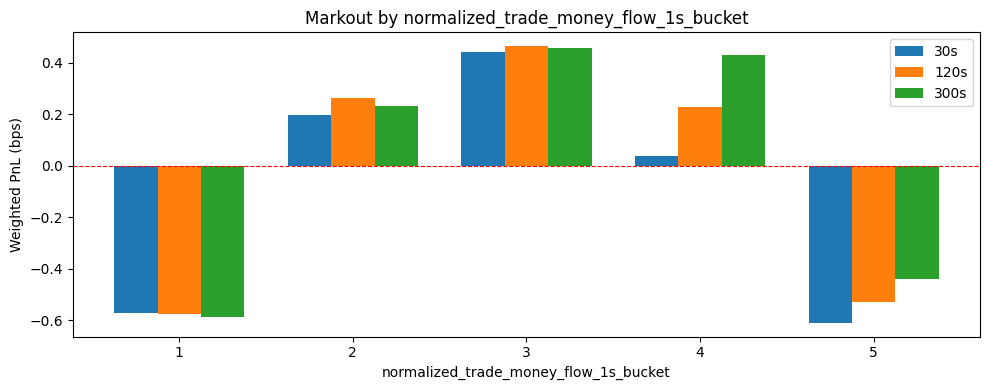

--- Stability ---
Train (Nov-Jan):


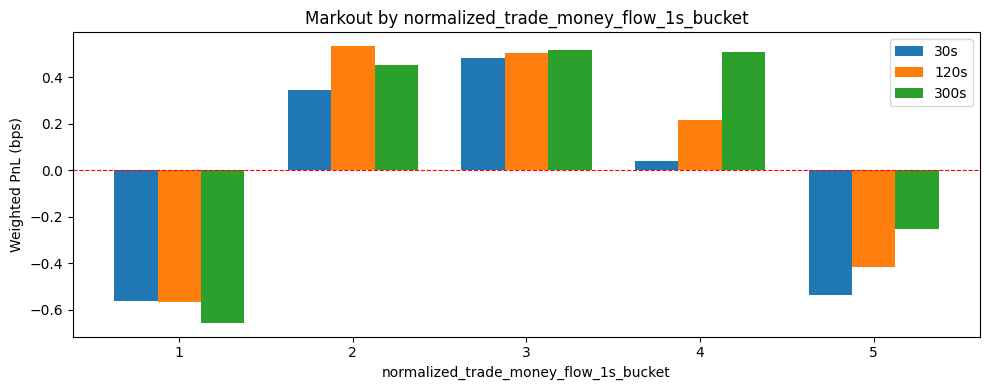

Validation (Feb-Apr):


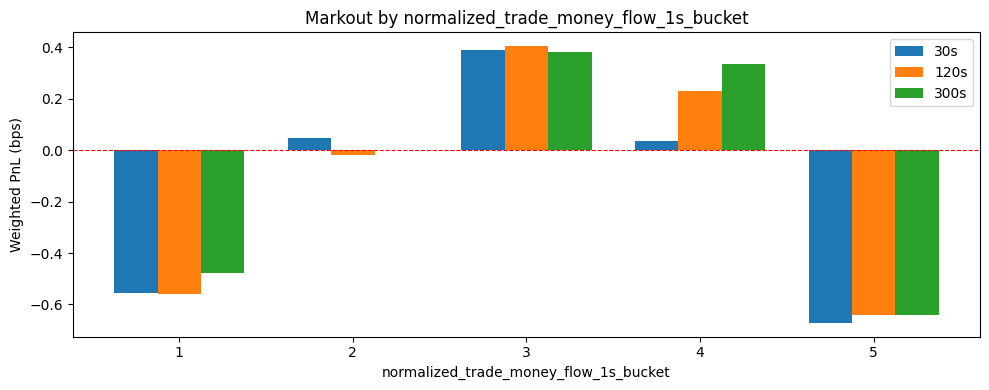

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0654,0.0
2,0.0312,1.5236e-141
3,0.0617,0.0
4,0.0334,1.2866e-161
5,0.0602,0.0



=== Window: 5s ===


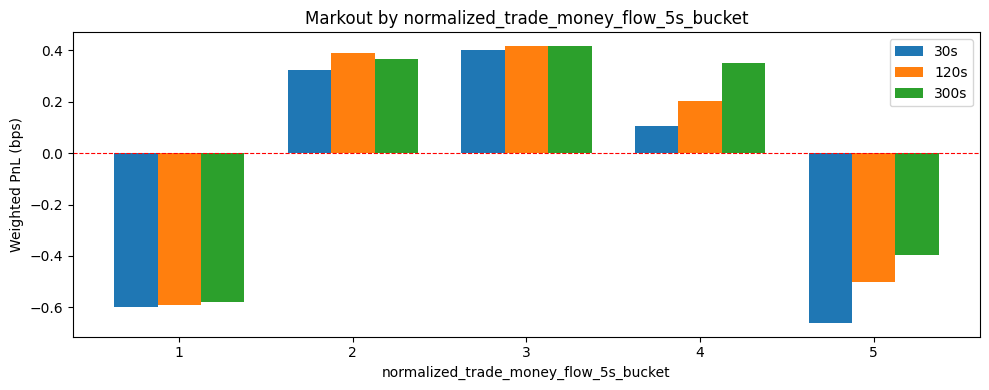

--- Stability ---
Train (Nov-Jan):


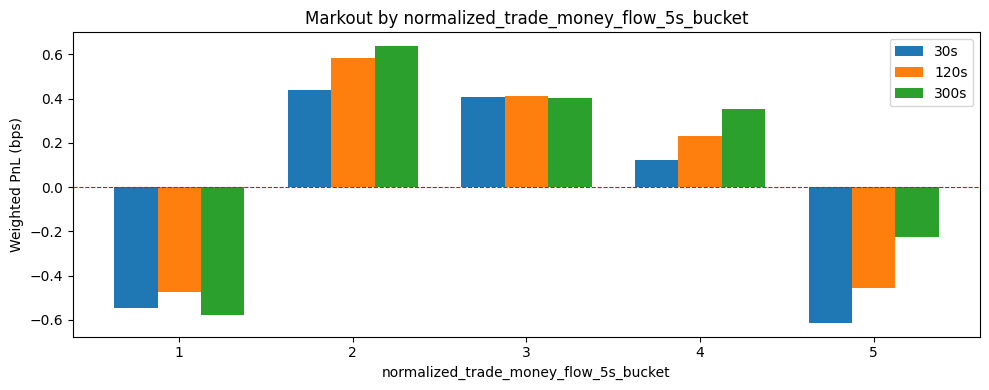

Validation (Feb-Apr):


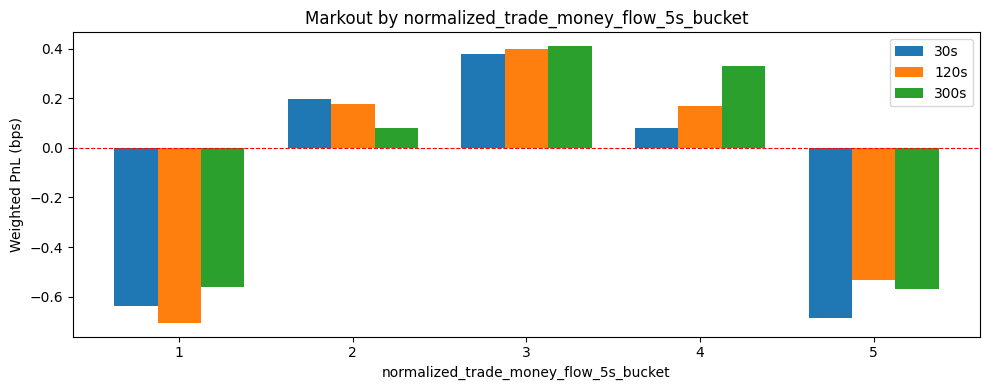

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0584,0.0
2,0.0333,8.0673e-161
3,0.0486,0.0
4,0.0334,3.0710e-162
5,0.0565,0.0



=== Window: 20s ===


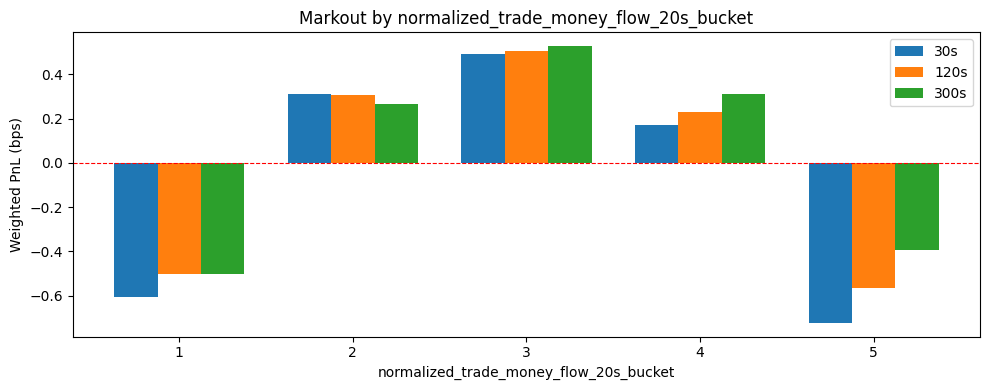

--- Stability ---
Train (Nov-Jan):


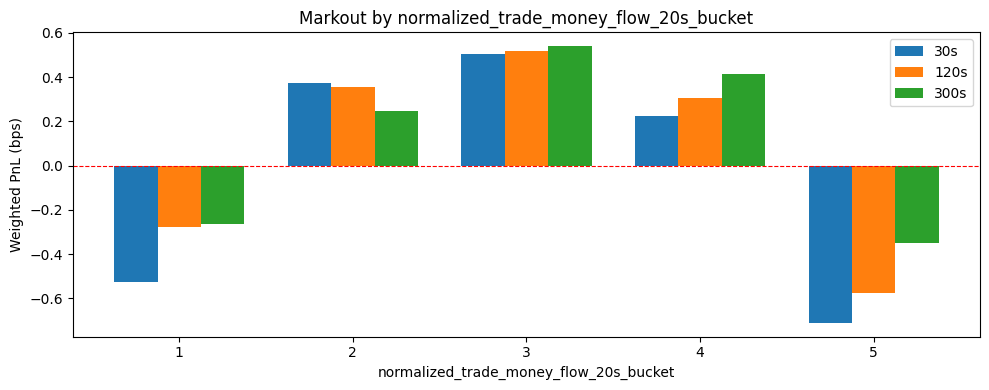

Validation (Feb-Apr):


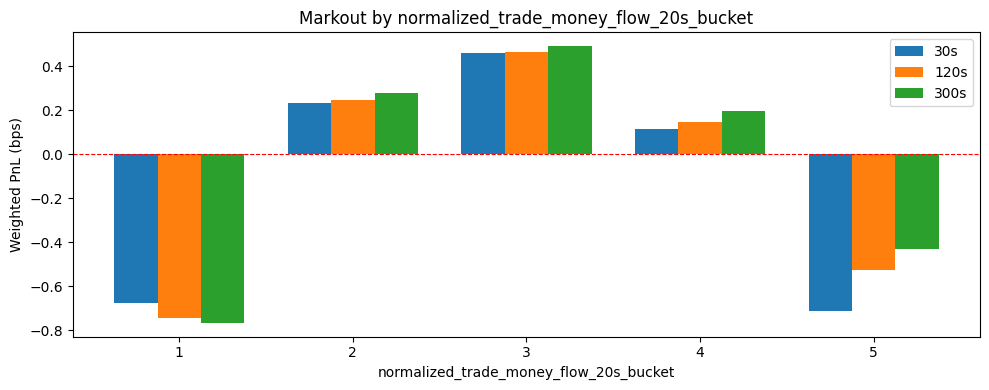

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0428,2.2101e-266
2,0.0234,5.5776e-80
3,0.0363,2.4630e-191
4,0.0258,7.6116e-97
5,0.0418,1.4256e-253


In [ ]:
# 3. Trade Flow (normalized).

df = utils.add_trade_flow_feature(
    lf_trades=lf_trades, lf_markout=lf_markout,
    windows_sec=[1, 5, 20], name_feature="normalized_trade_money_flow"
)

for w in [1, 5, 20]:
    col = f"normalized_trade_money_flow_{w}s"
    bucket = f"{col}_bucket"

    print(f"\n=== Window: {w}s ===")
    df = utils.add_quantile_buckets(df, col, n_buckets=5)

    result = utils.evaluate_class(df, bucket)
    display(result)
    utils.plot_class(result, bucket)

    print("--- Stability ---")
    r_train, r_val = utils.evaluate_class_by_period(df, bucket)

    print("Train (Nov-Jan):")
    utils.plot_class(r_train, bucket)

    print("Validation (Feb-Apr):")
    utils.plot_class(r_val, bucket)

    print("--- KS-test ---")
    display(utils.ks_test_class(df, bucket))

## <b>Class 4 - Liquidation Flow.</b>

Total liquidation dollar volume over recent windows. High liquidation volume signals forced selling/buying cascade. Bybit liquidations shifted +200ms to account for cross-exchange latency.


=== Window: 1s ===


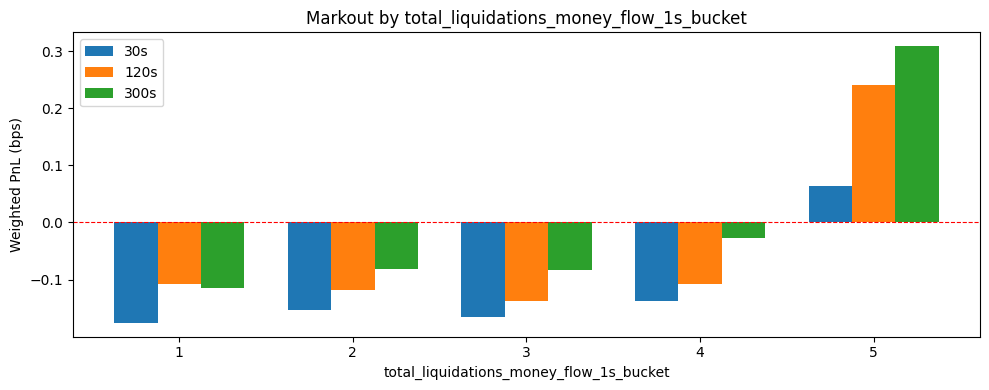

--- Stability ---
Train (Nov-Jan):


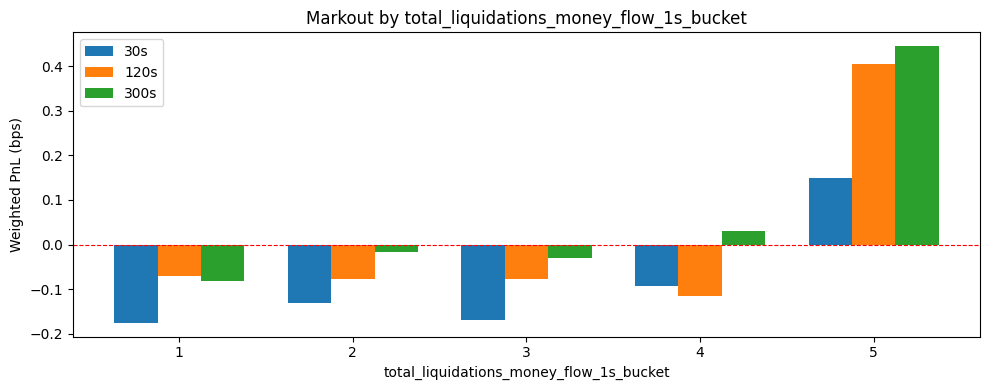

Validation (Feb-Apr):


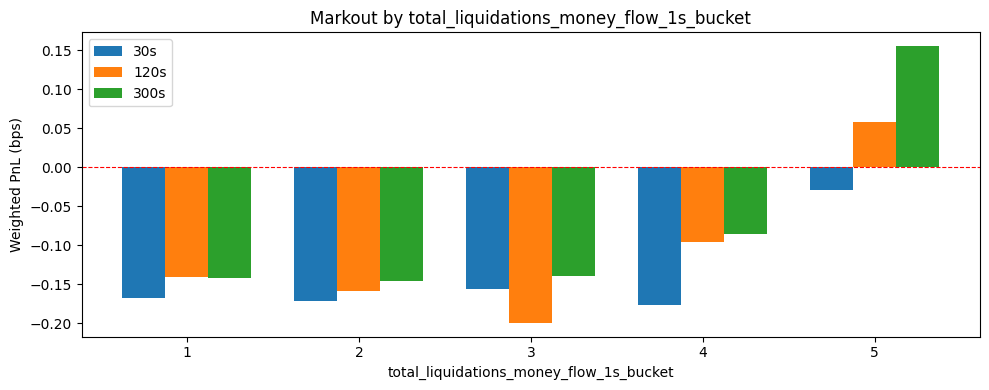

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0232,2.7107e-78
2,0.0145,8.4140e-31
3,0.0078,2.8641e-9
4,0.0063,0.000003
5,0.0398,2.4411e-229



=== Window: 5s ===


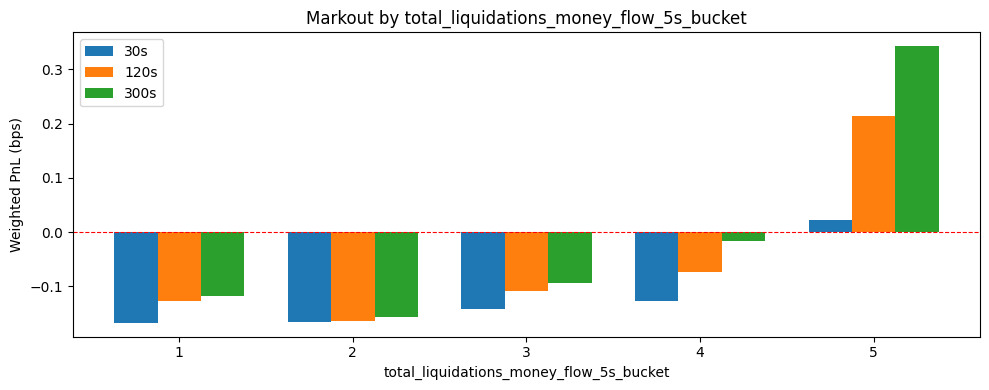

--- Stability ---
Train (Nov-Jan):


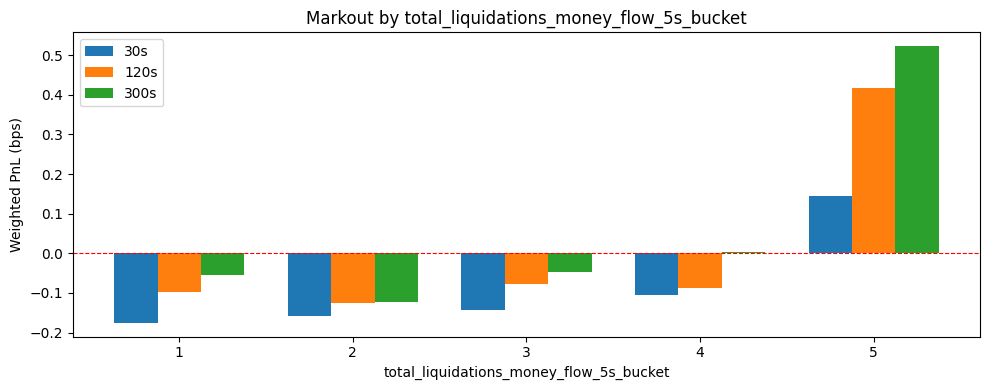

Validation (Feb-Apr):


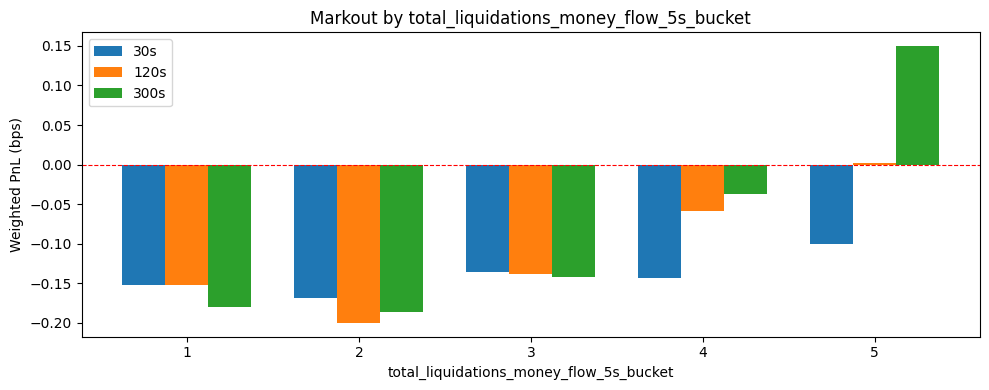

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0373,3.7003e-202
2,0.0269,1.8565e-105
3,0.0117,2.2740e-20
4,0.0101,3.9972e-15
5,0.0663,0.0



=== Window: 20s ===


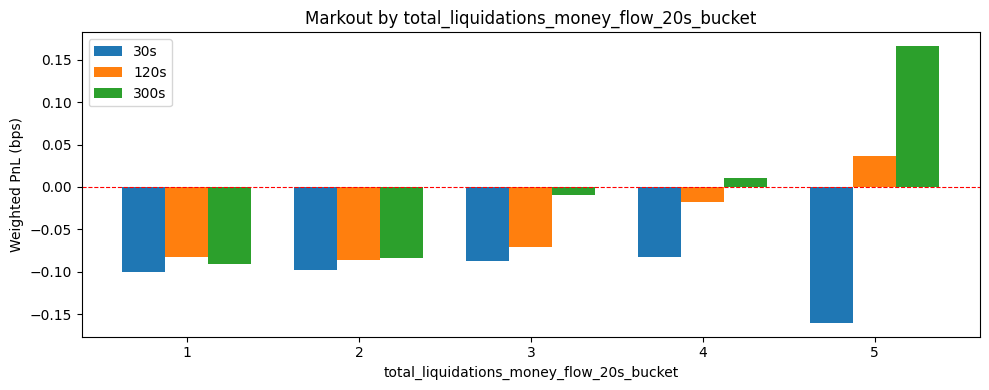

--- Stability ---
Train (Nov-Jan):


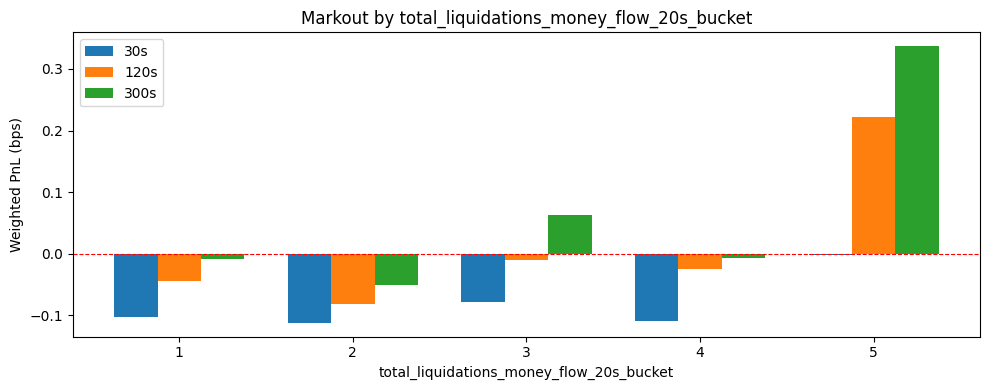

Validation (Feb-Apr):


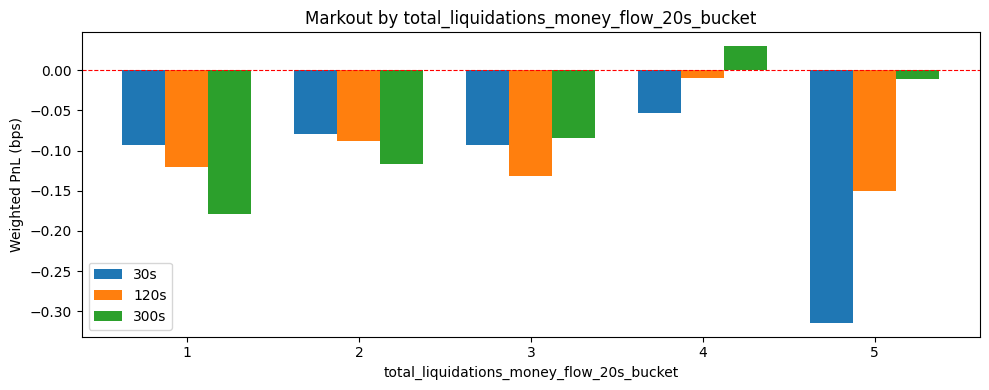

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0508,0.0
2,0.0344,5.1952e-172
3,0.0163,7.1400e-39
4,0.0196,4.9814e-56
5,0.0842,0.0


In [ ]:
# 4. Liquidations Flow (total).

df = utils.add_trade_liquidations_feature(
    lf_liq_bybit=lf_liq_bybit, lf_liq_binance=lf_liq_binance,
    lf_markout=lf_markout,
    windows_sec=[1, 5, 20], name_feature="total_liquidations_money_flow"
)

for w in [1, 5, 20]:
    col = f"total_liquidations_money_flow_{w}s"
    bucket = f"{col}_bucket"

    print(f"\n=== Window: {w}s ===")
    df = utils.add_quantile_buckets(df, col, n_buckets=5)

    result = utils.evaluate_class(df, bucket)
    display(result)
    utils.plot_class(result, bucket)

    print("--- Stability ---")
    r_train, r_val = utils.evaluate_class_by_period(df, bucket)

    print("Train (Nov-Jan):")
    utils.plot_class(r_train, bucket)
    
    print("Validation (Feb-Apr):")
    utils.plot_class(r_val, bucket)

    print("--- KS-test ---")
    display(utils.ks_test_class(df, bucket))


## <b>Class 5 - Realized Volatility.</b>

`RV = std(mid_price)` within each time bar. 

Measures short-term price uncertainty. Hypothesis: moderate volatility is toxic (transition), extreme volatility benefits maker (post-shock reversion).


=== Window: 5s ===


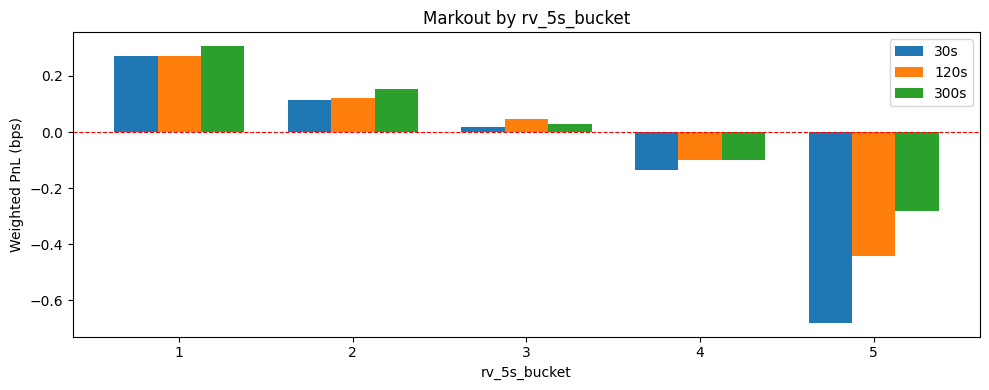

--- Stability ---
Train (Nov-Jan):


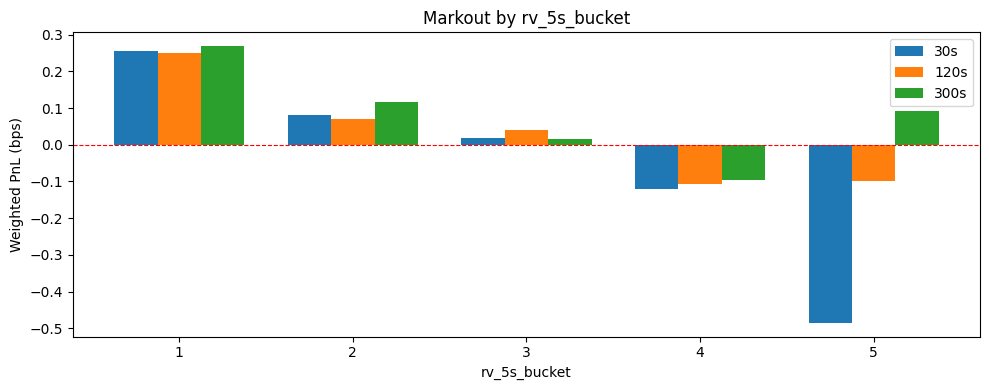

Validation (Feb-Apr):


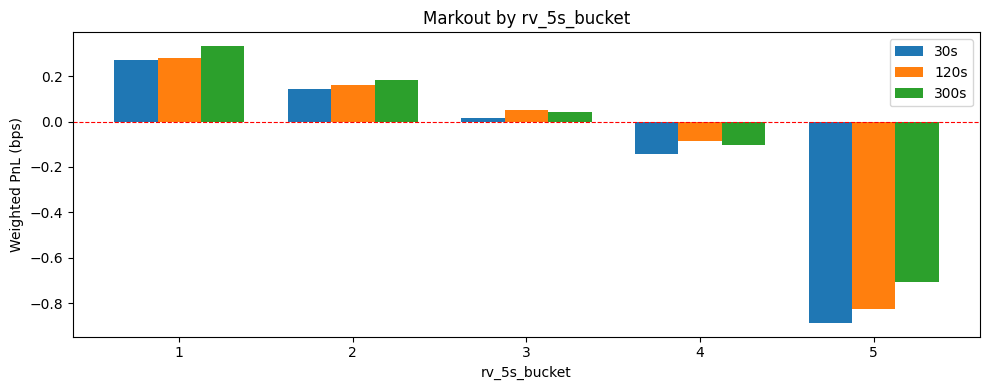

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.1262,0.0
2,0.0605,0.0
3,0.0202,1.8031e-59
4,0.0537,0.0
5,0.1424,0.0



=== Window: 20s ===


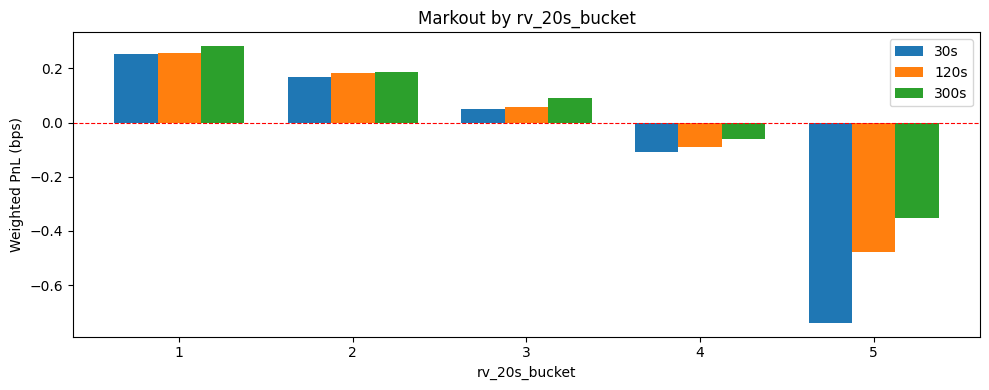

--- Stability ---
Train (Nov-Jan):


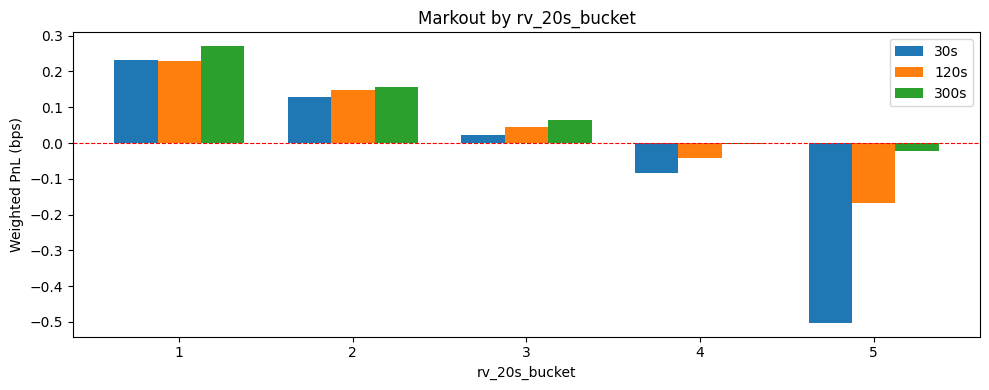

Validation (Feb-Apr):


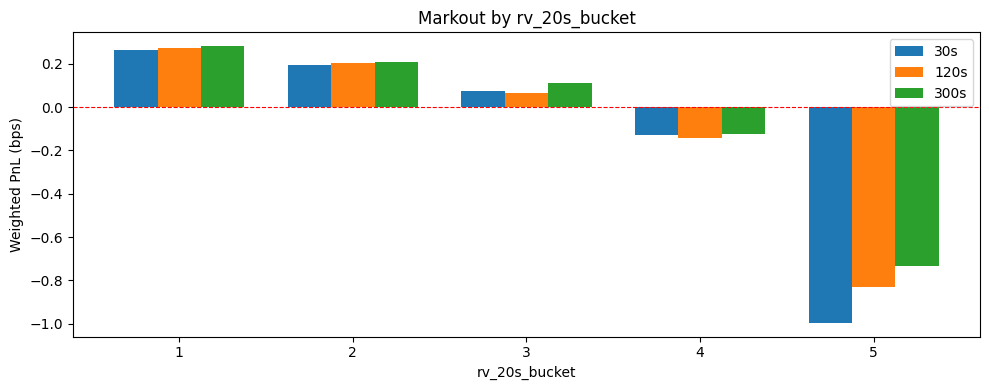

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.1638,0.0
2,0.0843,0.0
3,0.0336,6.9784e-164
4,0.0742,0.0
5,0.1808,0.0



=== Window: 60s ===


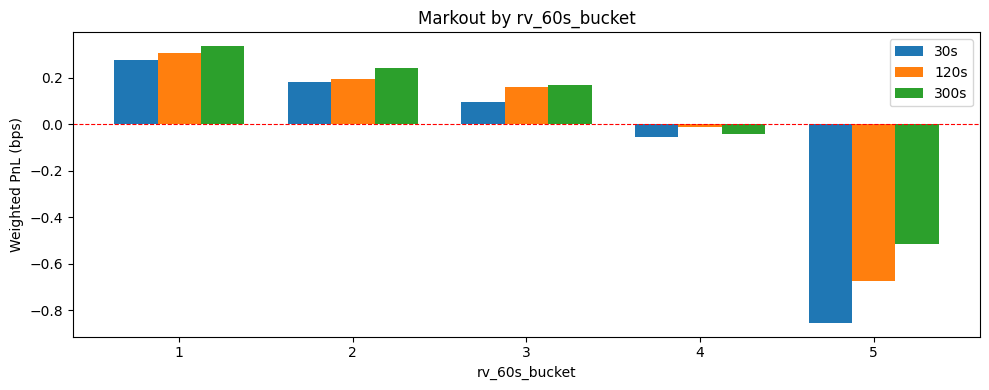

--- Stability ---
Train (Nov-Jan):


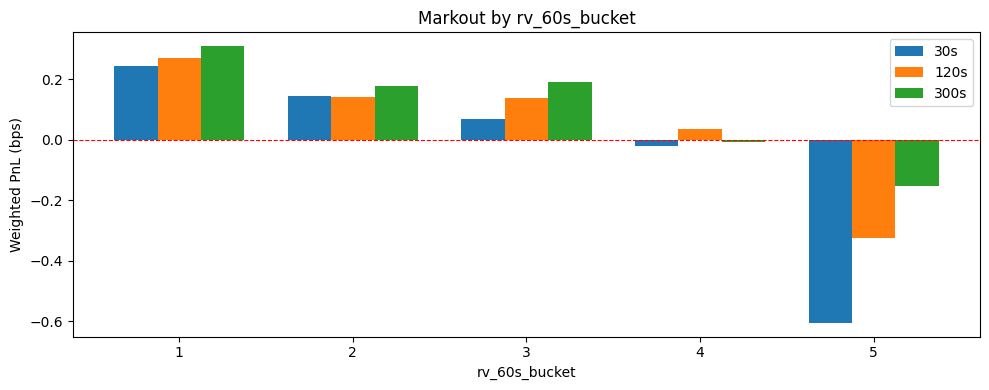

Validation (Feb-Apr):


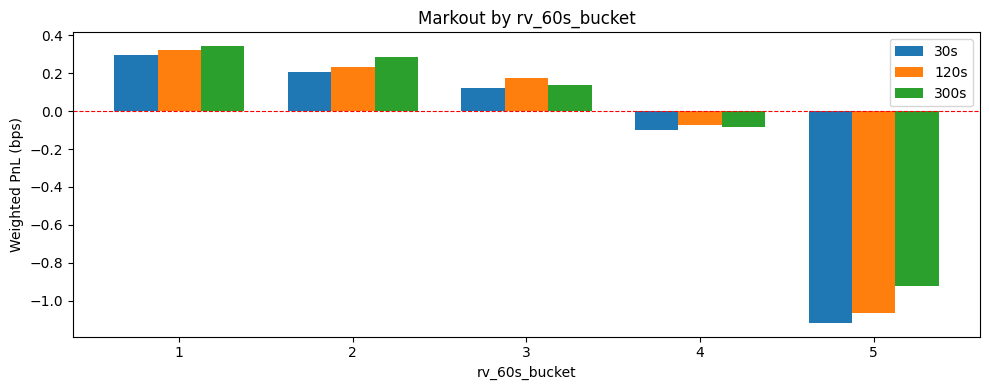

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.2119,0.0
2,0.114,0.0
3,0.0523,0.0
4,0.0998,0.0
5,0.2137,0.0


In [ ]:
# 5. Volatility.

df = utils.add_volatility_feature(
    lf_markout=lf_markout, lf_lob=lf_lob,
    windows_sec=[5, 20, 60]
)

for w in [5, 20, 60]:
    col = f"rv_{w}s"
    bucket = f"{col}_bucket"

    print(f"\n=== Window: {w}s ===")
    df = utils.add_quantile_buckets(df, col, n_buckets=5)

    result = utils.evaluate_class(df, bucket)
    display(result)
    utils.plot_class(result, bucket)

    print("--- Stability ---")
    r_train, r_val = utils.evaluate_class_by_period(df, bucket)

    print("Train (Nov-Jan):")
    utils.plot_class(r_train, bucket)
    
    print("Validation (Feb-Apr):")
    utils.plot_class(r_val, bucket)

    print("--- KS-test ---")
    display(utils.ks_test_class(df, bucket))


## <b>Class 6 - Order Flow Imbalance (Cont et al. 2014).</b>

OFI captures net change in order book depth: `OFI = Δ(bid_amount) - Δ(ask_amount)`, adjusted for price level changes. Aggregated into time bars of different sizes.

*Reference: Cont, Kukanov, Stoikov (2014). The Price Impact of Order Book Events.*


=== Window: 5s ===


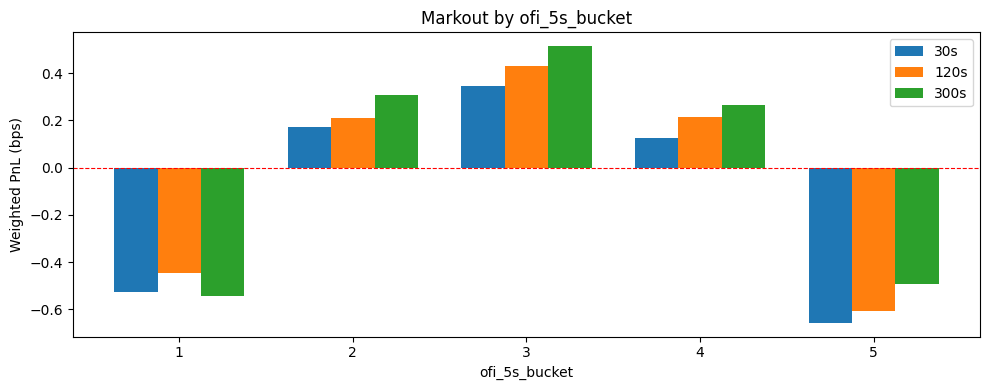

--- Stability ---
Train (Nov-Jan):


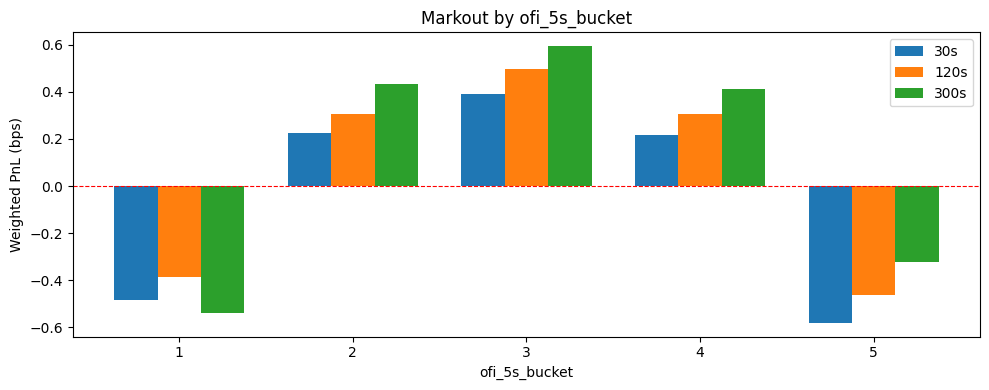

Validation (Feb-Apr):


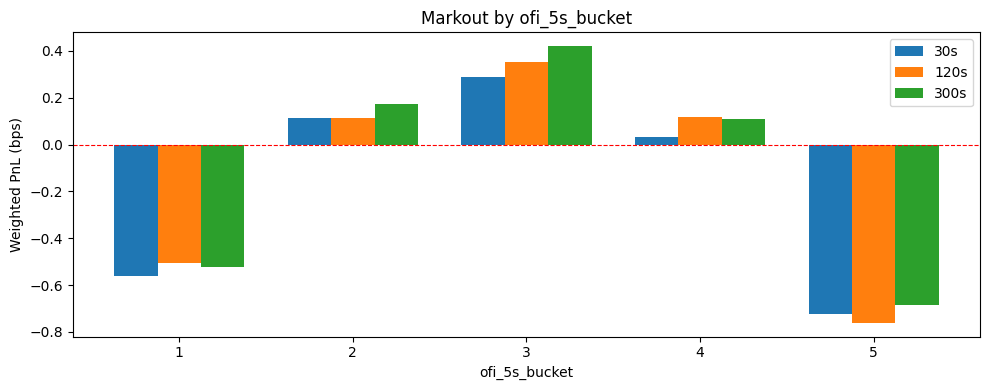

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0536,0.0
2,0.0197,2.3145e-56
3,0.0653,0.0
4,0.0213,5.4141e-66
5,0.051,0.0



=== Window: 15s ===


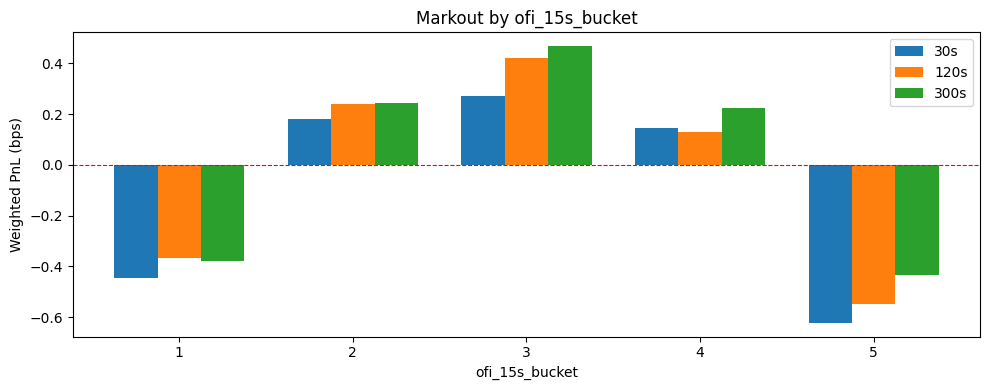

--- Stability ---
Train (Nov-Jan):


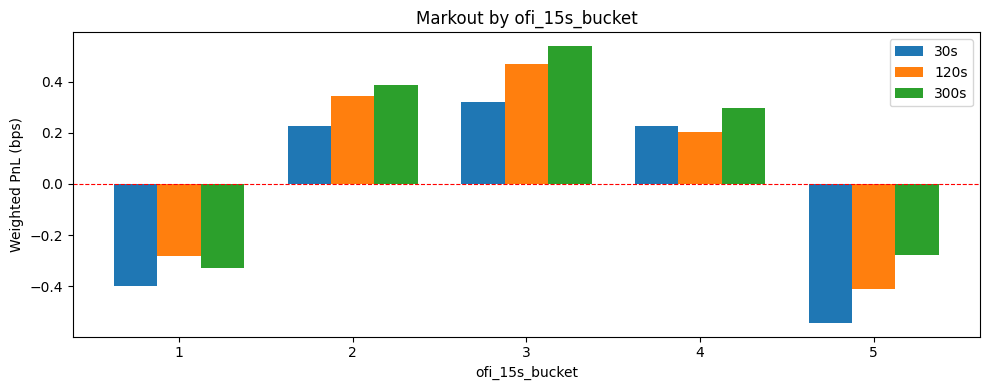

Validation (Feb-Apr):


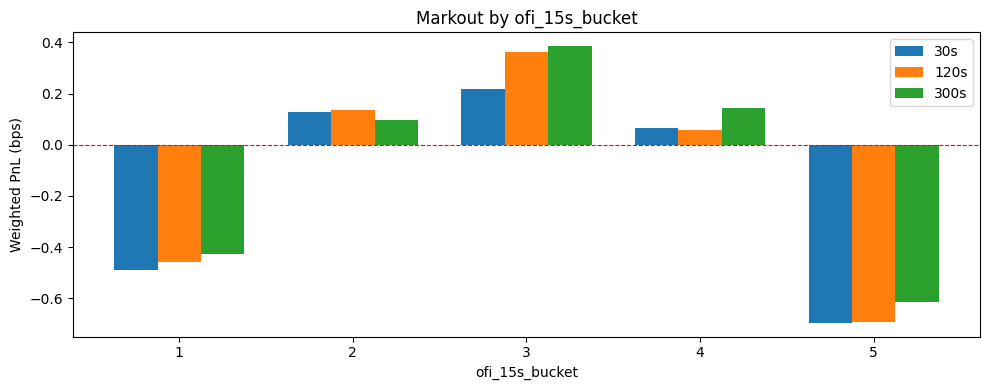

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0661,0.0
2,0.0293,3.6079e-125
3,0.073,0.0
4,0.0313,5.2425e-142
5,0.0648,0.0



=== Window: 60s ===


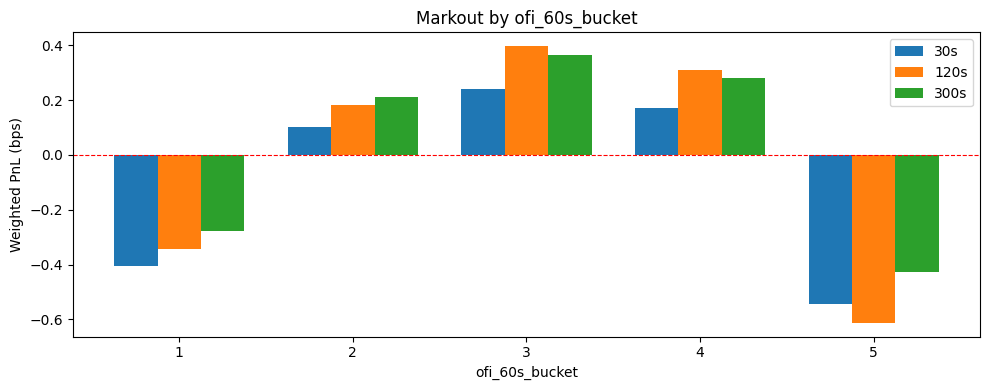

--- Stability ---
Train (Nov-Jan):


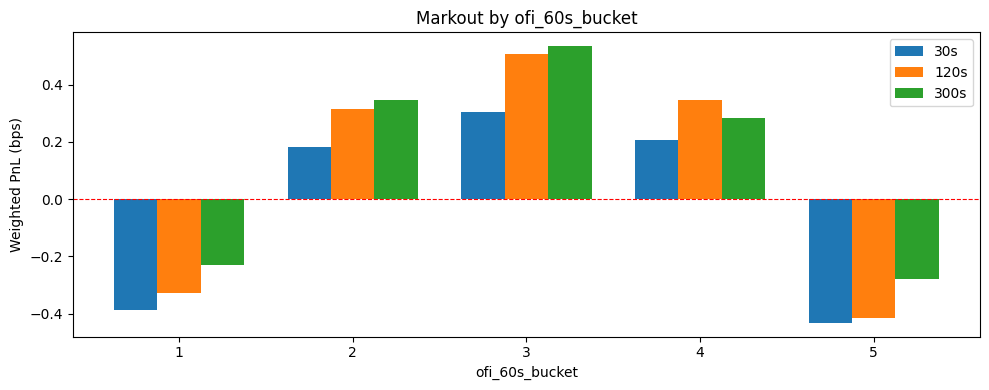

Validation (Feb-Apr):


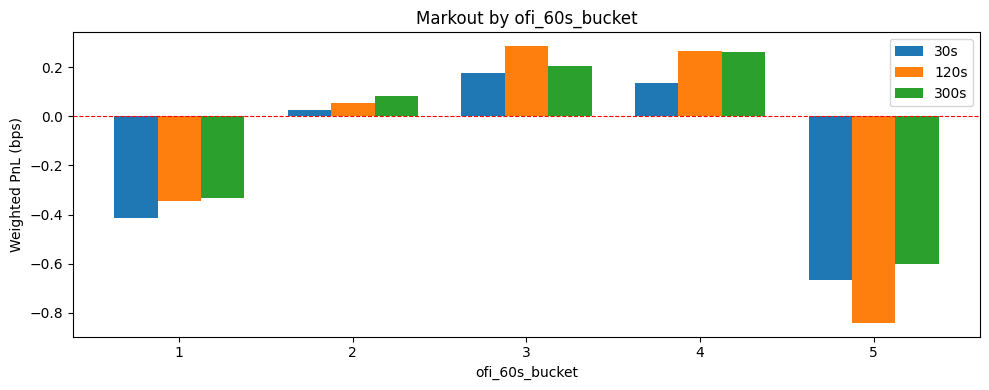

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0716,0.0
2,0.0321,3.6645e-149
3,0.0721,0.0
4,0.0353,1.2822e-180
5,0.0652,0.0


In [ ]:
# 6. OFI.

df = utils.add_ofi_feature(
    lf_markout=lf_markout, lf_lob=lf_lob,
    windows_sec=[5, 15, 60]
)

for w in [5, 15, 60]:
    col = f"ofi_{w}s"
    bucket = f"{col}_bucket"

    print(f"\n=== Window: {w}s ===")
    df = utils.add_quantile_buckets(df, col, n_buckets=5)

    result = utils.evaluate_class(df, bucket)
    display(result)
    utils.plot_class(result, bucket)

    print("--- Stability ---")
    r_train, r_val = utils.evaluate_class_by_period(df, bucket)

    print("Train (Nov-Jan):")
    utils.plot_class(r_train, bucket)
    
    print("Validation (Feb-Apr):")
    utils.plot_class(r_val, bucket)

    print("--- KS-test ---")
    display(utils.ks_test_class(df, bucket))

## <b>Class 7 - VPIN (Easley et al. 2012).</b>

Volume-Synchronized Probability of Informed Trading. Trades are grouped into equal-dollar volume buckets. For each bucket: `imbalance = |V_buy - V_sell| / V_total`. VPIN = rolling mean of imbalance. High VPIN = high probability of informed trading = toxic for maker.

*Reference: Easley, López de Prado, O'Hara (2012). Flow Toxicity and Liquidity in a High-Frequency World.*


=== Smoothing: 10 buckets ===


vpin_10_bucket,turnover,w_pnl_30s,w_pnl_120s,w_pnl_300s,turnover_pct
u8,f32,f32,f32,f32,f32
1,3.8415e11,0.0898,0.1308,0.1921,18.17
2,4.0306e11,-0.025,0.051,0.0992,19.07
3,4.1906e11,-0.1811,-0.0458,-0.0227,19.82
4,4.3700e11,-0.1452,-0.0914,-0.0378,20.67
5,4.7083e11,-0.245,-0.1989,-0.1441,22.27


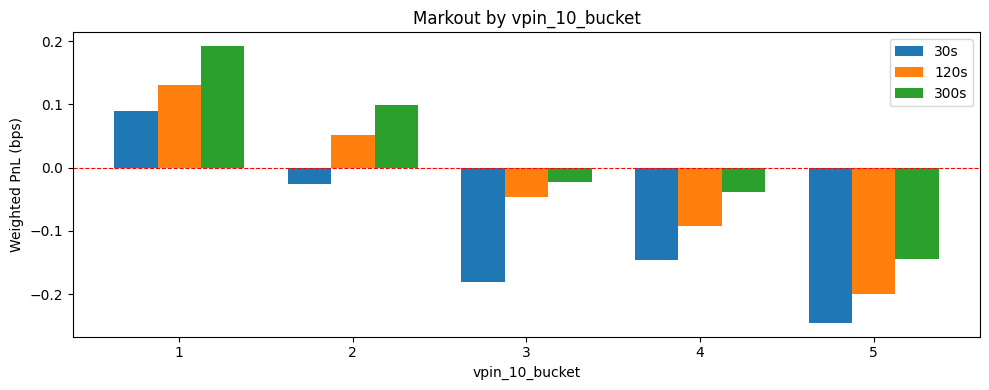

--- Stability ---
Train (Nov-Jan):


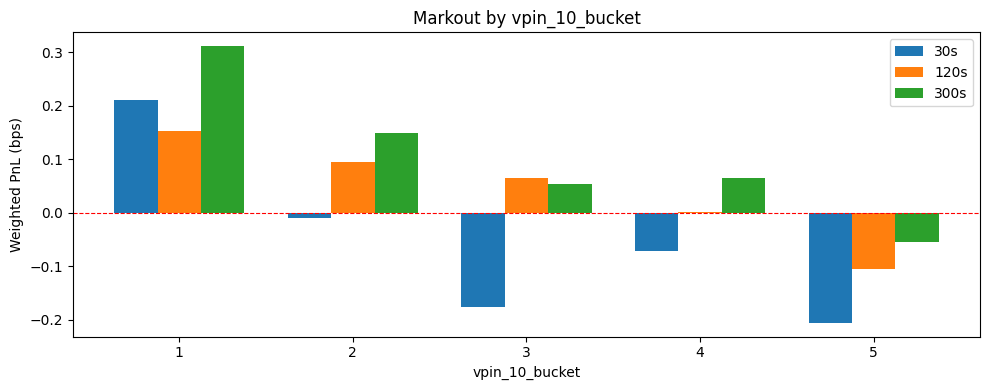

Validation (Feb-Apr):


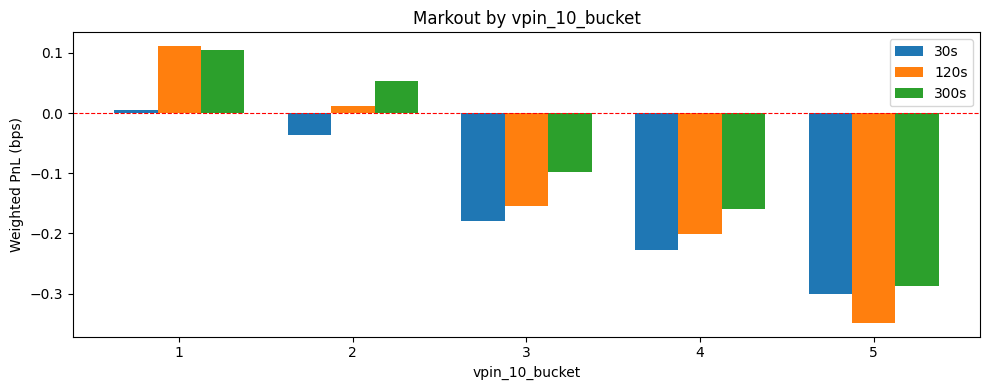

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0525,0.0
2,0.0184,1.5487e-49
3,0.006,0.00001
4,0.0205,5.5890e-61
5,0.0469,1.7193e-317



=== Smoothing: 50 buckets ===


vpin_50_bucket,turnover,w_pnl_30s,w_pnl_120s,w_pnl_300s,turnover_pct
u8,f32,f32,f32,f32,f32
1,3.9199e11,0.028,0.2471,0.2757,18.549999
2,3.9934e11,-0.1057,-0.0827,0.0195,18.9
3,4.1530e11,-0.148,-0.0882,-0.0981,19.65
4,4.3484e11,-0.1066,-0.1076,-0.0712,20.58
5,4.7182e11,-0.1932,-0.1321,-0.0513,22.33


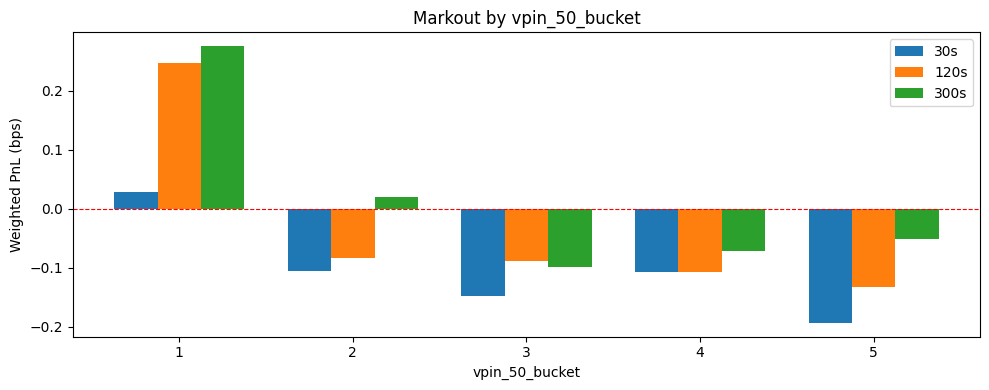

--- Stability ---
Train (Nov-Jan):


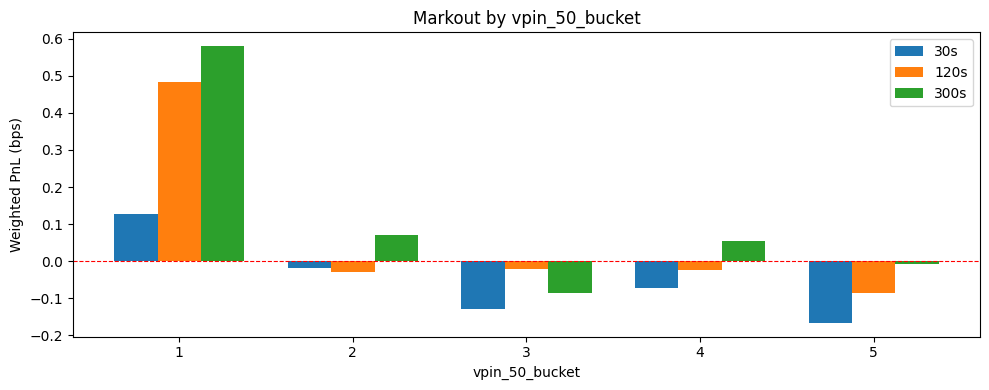

Validation (Feb-Apr):


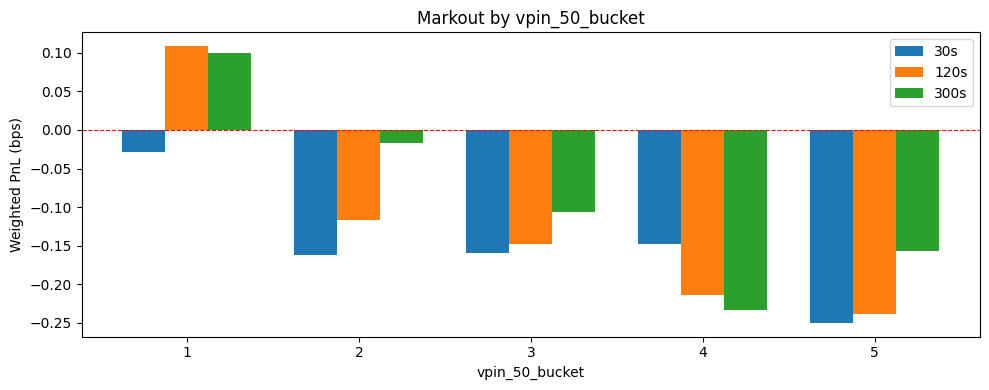

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0973,0.0
2,0.022,2.5372e-70
3,0.0145,4.4785e-31
4,0.0359,3.0483e-187
5,0.0697,0.0


In [ ]:
# 7. VPIN.

df = utils.add_vpin_feature(
    lf_markout=lf_markout, lf_trades=lf_trades,
    bucket_volume_usd=500_000, smoothing_windows=[10, 50]
)

for n in [10, 50]:
    col = f"vpin_{n}"
    bucket = f"{col}_bucket"

    print(f"\n=== Smoothing: {n} buckets ===")
    df = utils.add_quantile_buckets(df, col, n_buckets=5)

    result = utils.evaluate_class(df, bucket)
    display(result)
    utils.plot_class(result, bucket)

    print("--- Stability ---")
    r_train, r_val = utils.evaluate_class_by_period(df, bucket)

    print("Train (Nov-Jan):")
    utils.plot_class(r_train, bucket)
    
    print("Validation (Feb-Apr):")
    utils.plot_class(r_val, bucket)

    print("--- KS-test ---")
    display(utils.ks_test_class(df, bucket))

## <b>Class 8 - Amihud Illiquidity (Amihud 2002).</b>

`Amihud = |return| / volume` per time bar. Measures price impact per dollar traded. High Amihud = illiquid market = each trade moves price more = dangerous for maker.

*Reference: Amihud (2002). Illiquidity and Stock Returns.*


=== Window: 5s ===


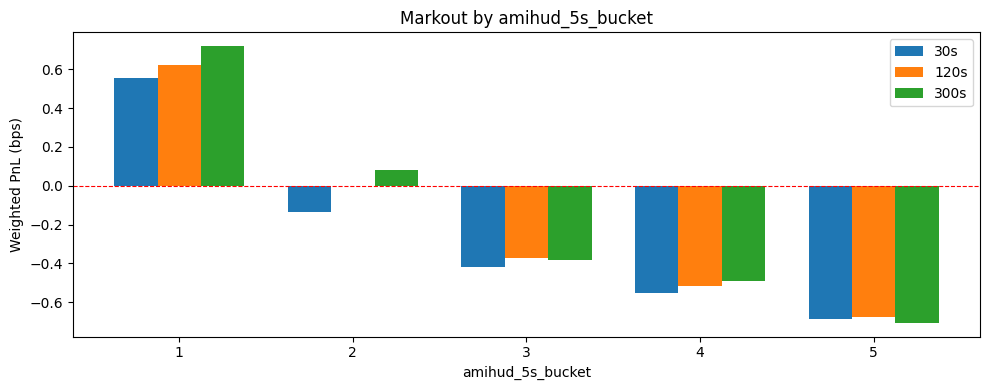

--- Stability ---
Train (Nov-Jan):


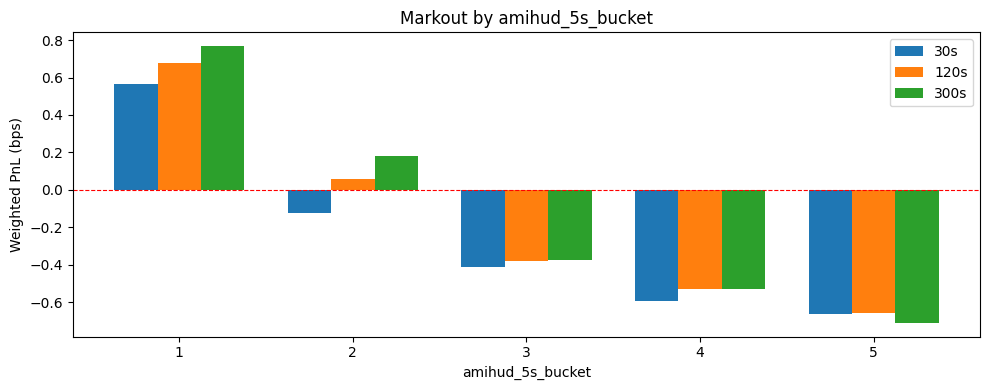

Validation (Feb-Apr):


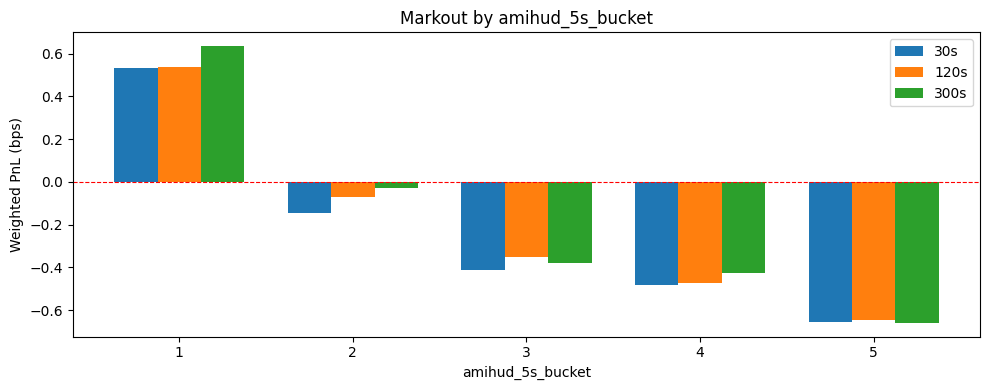

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0657,0.0
2,0.0474,0.0
3,0.0126,1.7191e-23
4,0.0277,3.0893e-111
5,0.0772,0.0



=== Window: 20s ===


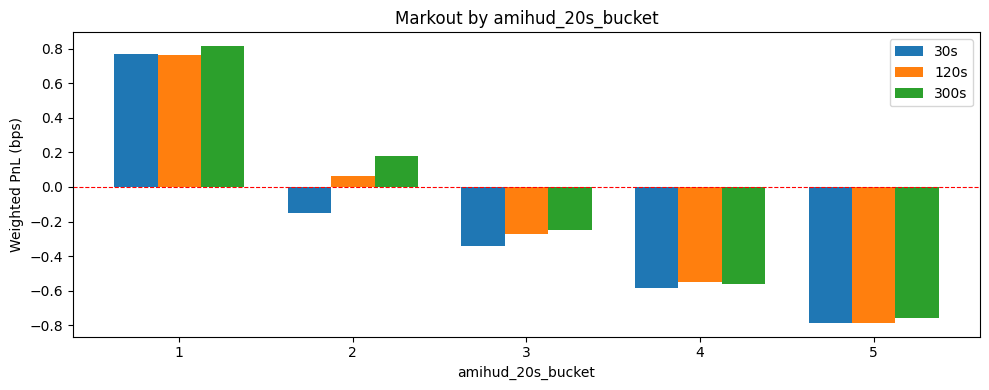

--- Stability ---
Train (Nov-Jan):


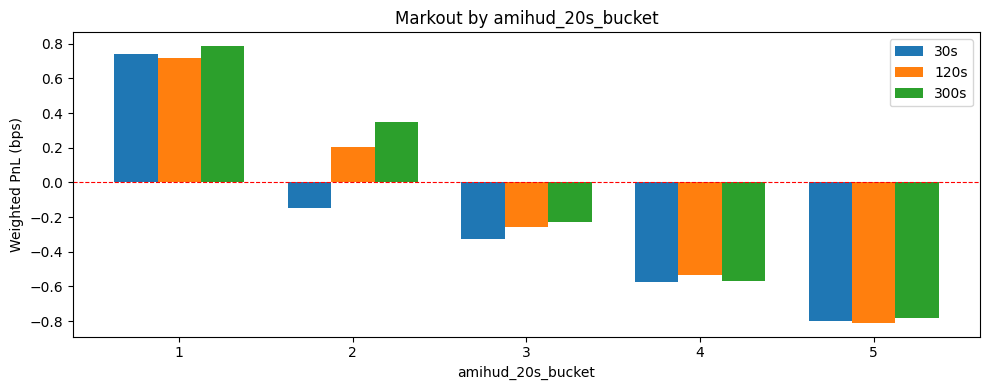

Validation (Feb-Apr):


c:\Users\Klimn\Desktop\HFT_School_2\utilities.py:721: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


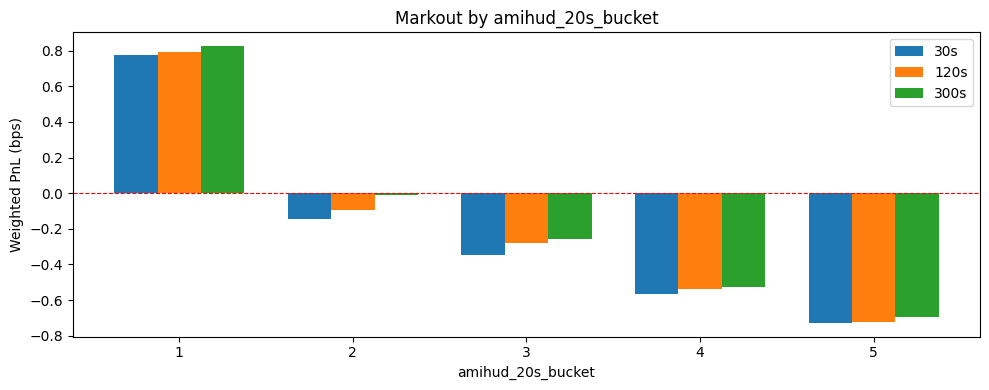

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0717,0.0
2,0.0432,2.0883e-270
3,0.0118,1.4981e-20
4,0.0258,3.9333e-97
5,0.088,0.0



=== Window: 60s ===


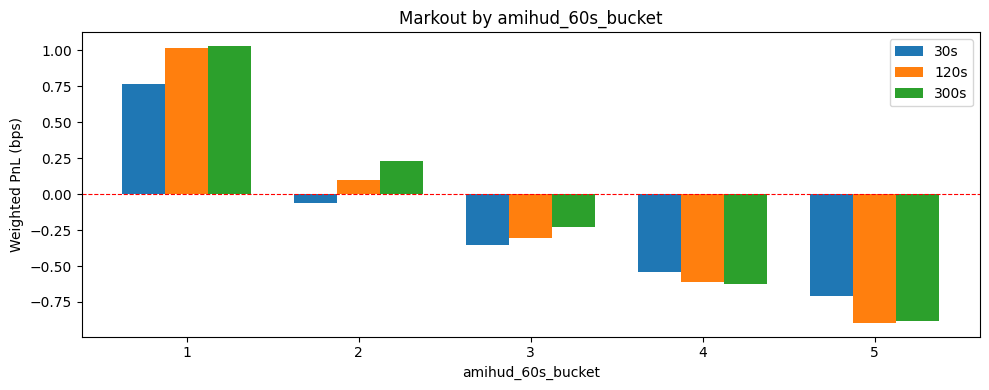

--- Stability ---
Train (Nov-Jan):


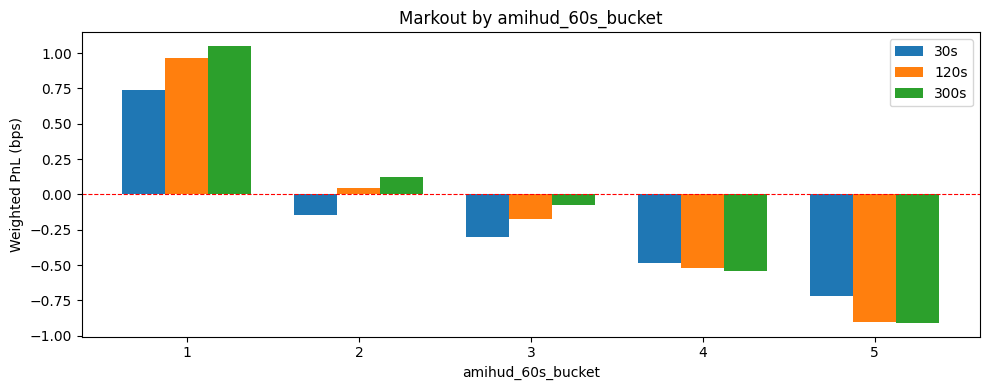

Validation (Feb-Apr):


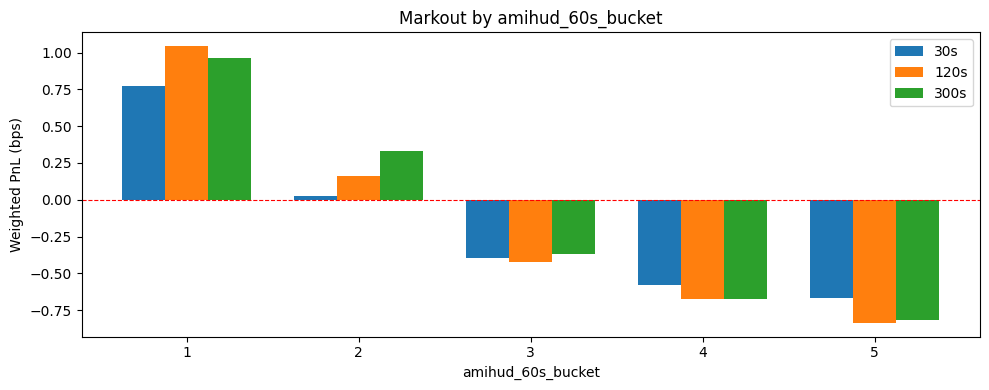

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0541,0.0
2,0.0346,5.7712e-174
3,0.0111,4.4208e-18
4,0.0203,3.4741e-60
5,0.0733,0.0


In [ ]:
# 8. Amihud.

df = utils.add_amihud_feature(
    lf_markout=lf_markout, lf_lob=lf_lob, lf_trades=lf_trades,
    windows_sec=[5, 20, 60]
)

for w in [5, 20, 60]:
    col = f"amihud_{w}s"
    bucket = f"{col}_bucket"

    print(f"\n=== Window: {w}s ===")
    df = utils.add_quantile_buckets(df, col, n_buckets=5)

    result = utils.evaluate_class(df, bucket)
    display(result)
    utils.plot_class(result, bucket)

    print("--- Stability ---")
    r_train, r_val = utils.evaluate_class_by_period(df, bucket)

    print("Train (Nov-Jan):")
    utils.plot_class(r_train, bucket)
    
    print("Validation (Feb-Apr):")
    utils.plot_class(r_val, bucket)

    print("--- KS-test ---")
    display(utils.ks_test_class(df, bucket))

## <b>Class 9 - Microprice Deviation (Stoikov 2018).</b>

`microprice = ask × bid_vol/(bid_vol + ask_vol) + bid × ask_vol/(bid_vol + ask_vol)`

`deviation = (microprice - mid) / half_spread`

Bounded [-1, +1]. Positive = short-term price pressure upward. Microprice is a better estimator of future price than mid.

*Reference: Stoikov (2018). The Micro-Price: A High-Frequency Estimator of Future Prices.*

microprice_dev_bucket,turnover,w_pnl_30s,w_pnl_120s,w_pnl_300s,turnover_pct
u8,f32,f32,f32,f32,f32
1,2.3953e11,-0.1755,-0.098,-0.0799,11.33
2,5.0534e11,-0.1134,-0.0667,-0.0552,23.91
3,6.2689e11,-0.0886,-0.0138,0.0448,29.66
4,5.0357e11,-0.1235,-0.064,-0.017,23.82
5,2.3853e11,-0.0553,0.0675,0.199,11.28


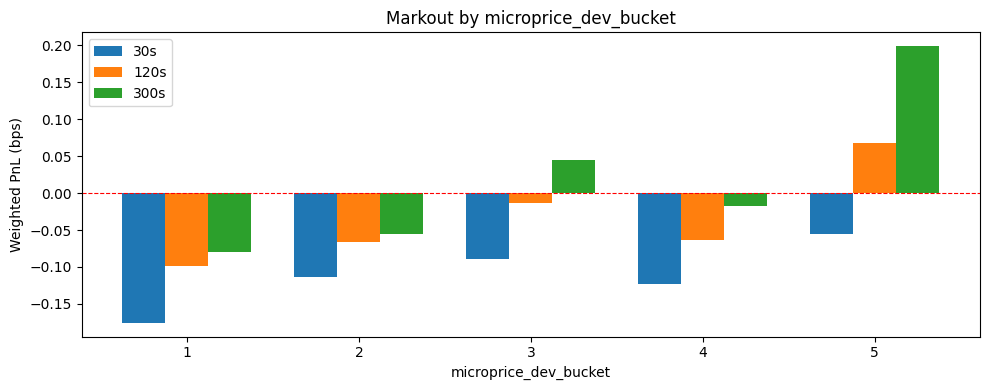

--- Stability ---
Train (Nov-Jan):


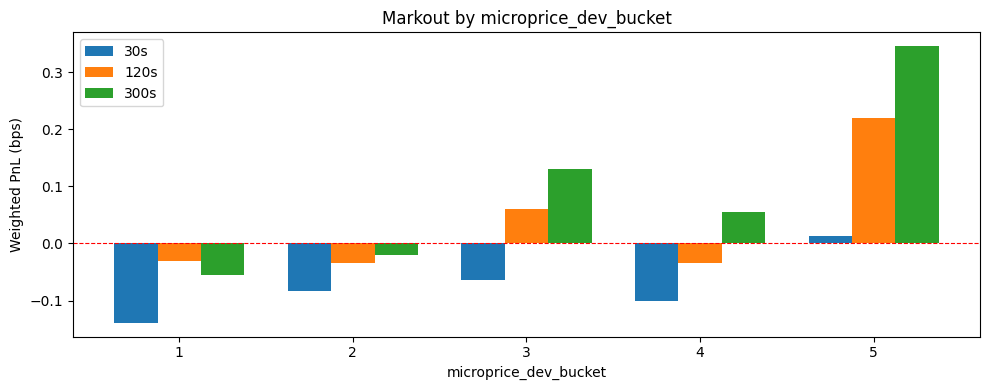

Validation (Feb-Apr):


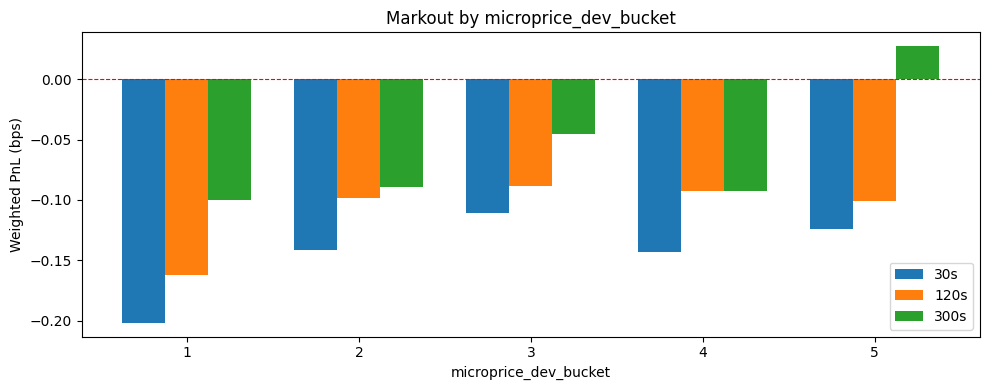

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.0149,2.2237e-32
2,0.003,0.099034
3,0.0161,6.5675e-38
4,0.0079,1.5452e-9
5,0.0073,3.0863e-8


In [ ]:
# 9. Microprice Deviation.

df = utils.add_microprice_deviation_feature(lf_lob=lf_lob, lf_markout=lf_markout)
df = utils.add_quantile_buckets(df, "microprice_dev", n_buckets=5)

result = utils.evaluate_class(df, "microprice_dev_bucket")
display(result)
utils.plot_class(result, "microprice_dev_bucket")

print("--- Stability ---")
r_train, r_val = utils.evaluate_class_by_period(df, "microprice_dev_bucket")

print("Train (Nov-Jan):")
utils.plot_class(r_train, "microprice_dev_bucket")
    
print("Validation (Feb-Apr):")
utils.plot_class(r_val, "microprice_dev_bucket")

print("--- KS-test ---")
display(utils.ks_test_class(df, "microprice_dev_bucket"))

## <b>Class 10 - Distance to Mid.</b>

`dist_to_mid = (trade_price - mid) / mid × 10_000` in bps. 

Measures how far from fair value the trade executed. Large negative distance = taker sold aggressively below mid -> maker bought at discount -> price reverts -> positive markout.

dist_to_mid_bucket,turnover,w_pnl_30s,w_pnl_120s,w_pnl_300s,turnover_pct
u8,f32,f32,f32,f32,f32
1,3.3945e11,0.2902,0.5308,0.572,16.059999
2,3.6611e11,-0.2567,-0.2679,-0.2542,17.32
3,7.0407e11,-0.1138,-0.1033,-0.0852,33.32
4,3.7210e11,-0.2659,-0.2484,-0.1958,17.610001
5,3.3157e11,-0.1681,0.0026,0.1545,15.69


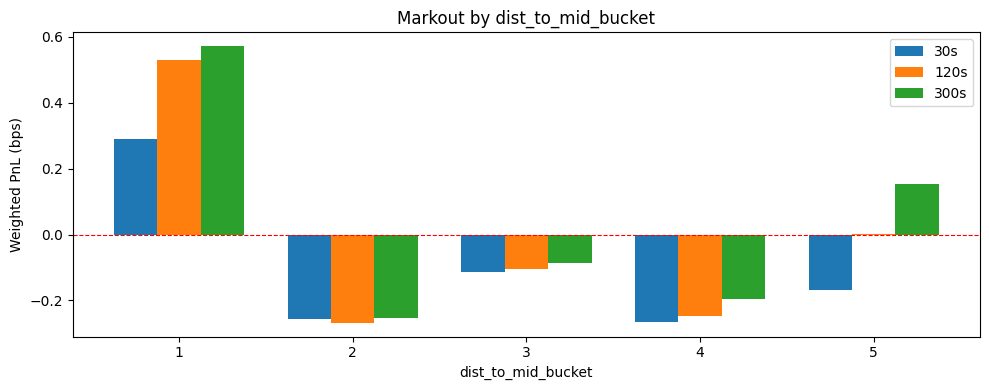

--- Stability ---
Train (Nov-Jan):


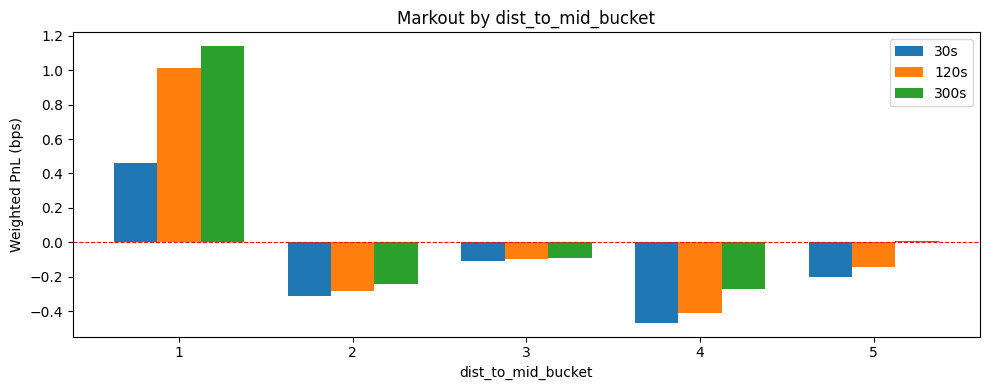

Validation (Feb-Apr):


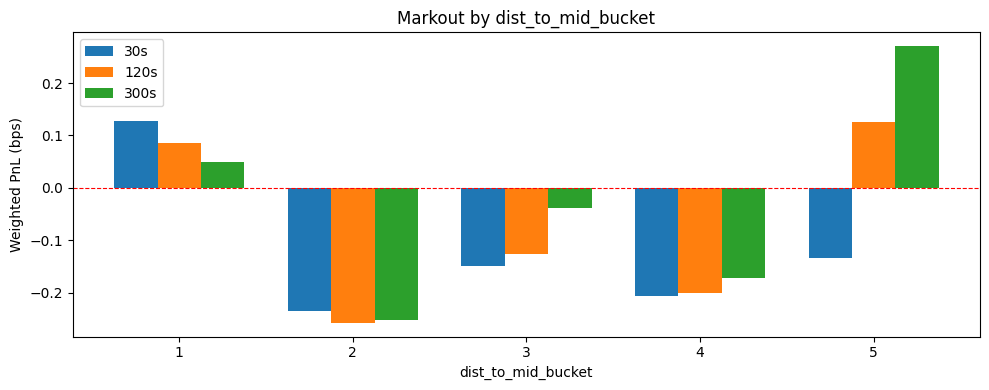

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
1,0.03,3.9956e-131
2,0.0169,1.3683e-41
3,0.043,4.2874e-269
4,0.0104,5.9953e-16
5,0.0335,8.6207e-163


In [5]:
# 10. Distance to Mid.

df = utils.add_distance_to_mid_feature(lf_lob=lf_lob, lf_markout=lf_markout)
df = utils.add_quantile_buckets(df, "dist_to_mid", n_buckets=5)

result = utils.evaluate_class(df, "dist_to_mid_bucket")
display(result)
utils.plot_class(result, "dist_to_mid_bucket")

print("--- Stability ---")
r_train, r_val = utils.evaluate_class_by_period(df, "dist_to_mid_bucket")

print("Train (Nov-Jan):")
utils.plot_class(r_train, "dist_to_mid_bucket")

print("Validation (Feb-Apr):")
utils.plot_class(r_val, "dist_to_mid_bucket")

print("--- KS-test ---")
display(utils.ks_test_class(df, "dist_to_mid_bucket"))


## <b>Class 11 - Hour of Day.</b>

UTC hour extracted from trade timestamp. Captures intraday seasonality in adverse selection - e.g., US market open (14:00 UTC) vs Asian session (00:00–08:00 UTC).

hour_utc,turnover,w_pnl_30s,w_pnl_120s,w_pnl_300s,turnover_pct
u8,f32,f32,f32,f32,f32
0,8.2777e10,-0.1755,-0.386,-0.6562,3.79
1,8.1863e10,-0.2729,-0.3896,-0.4253,3.75
2,7.5250e10,-0.171,-0.0883,0.0094,3.45
3,6.8731e10,-0.0585,-0.0936,-0.1327,3.15
4,6.3498e10,0.0077,0.0244,-0.1498,2.91
…,…,…,…,…,…
19,8.8992e10,0.0013,0.1962,0.2312,4.08
20,8.1128e10,-0.1218,0.0654,0.1898,3.72
21,6.1522e10,-0.4566,-0.2285,-0.1967,2.82


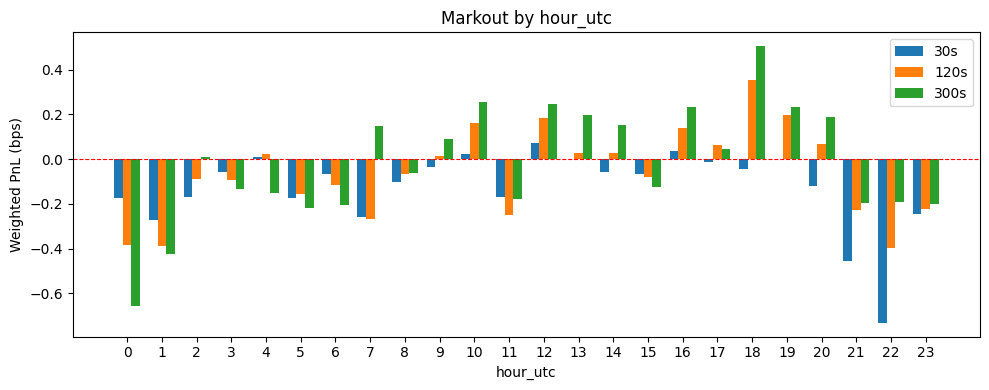

--- Stability ---
Train (Nov-Jan):


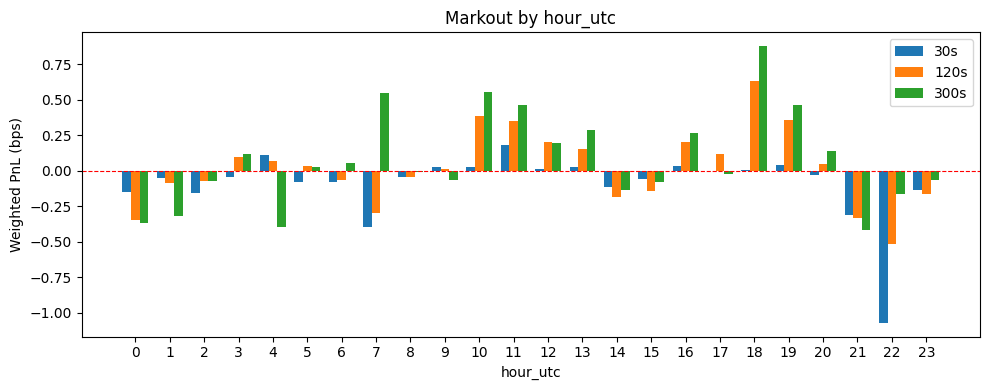

Validation (Feb-Apr):


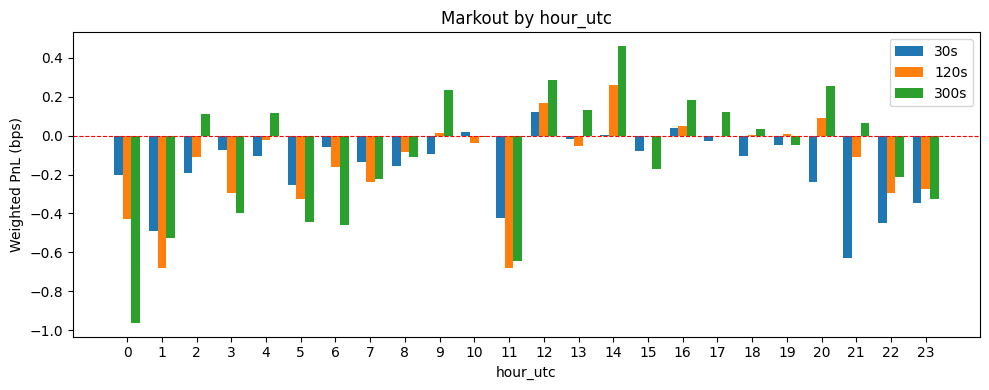

--- KS-test ---


bucket,ks_stat,p_value
i64,f64,f64
0,0.0136,0.000002
1,0.0197,1.4057e-13
2,0.0239,4.2855e-18
3,0.0437,3.3040e-53
4,0.0608,4.2504e-92
…,…,…
19,0.0094,0.001257
20,0.009,0.004834
21,0.0347,6.7811e-30


In [5]:
# 11. Hour of Day.

df = utils.add_hour_feature(lf_markout=lf_markout)

result = utils.evaluate_class(df, "hour_utc")
display(result)
utils.plot_class(result, "hour_utc")

print("--- Stability ---")
r_train, r_val = utils.evaluate_class_by_period(df, "hour_utc")

print("Train (Nov-Jan):")
utils.plot_class(r_train, "hour_utc")

print("Validation (Feb-Apr):")
utils.plot_class(r_val, "hour_utc")

print("--- KS-test ---")
display(utils.ks_test_class(df, "hour_utc"))